# Quickstart

In this tutorial we grow one tumor with `iscc`, cut the resected specimen in two, and generate one data set for each of bulk whole-genome sequencing (WGS), single-cell DNA sequencing (scDNA), single-cell RNA sequencing (scRNA) and Visium spatial transcriptomics.
Every data set comes with an answer key that gives the clone, copy number, cell type and niche of each cell it measured, and we read the answer key next to the data.
The notebook runs in about three minutes on a laptop.

The other tutorials go deeper into each step.
[Shape the tumor](02_shape_the_tumor.ipynb) changes the tumor through its configuration, [Shape the data](03_shape_the_data.ipynb) changes the assays and their biases, and [Simulate a cohort](04_cohort.ipynb) grows many patients over one configuration.

In [1]:
import os
import warnings
os.environ["KMP_WARNINGS"] = "0"  # silence a deprecation notice of OpenMP in the UMAP dependencies
warnings.filterwarnings("ignore", category=FutureWarning)
warnings.filterwarnings("ignore", category=RuntimeWarning, module="numba")
warnings.filterwarnings("ignore", message="IProgress not found")
warnings.filterwarnings("ignore", message="max_cells")  # the dissociated sample is a subsample by design

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import scanpy as sc
import squidpy as sq

from iscc.constants import normal_names
from iscc.data import bulkDNA, scDNA, scRNA, Visium
from iscc.integrations import biological_types, clone_summary, clones_from_clades
from iscc.sample import Resection
from iscc.tumor import GenotypeTumor
from iscc.tumor.viz import CNV_CMAP, cnv_norm

## Grow a tumor

We build a [`GenotypeTumor`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) from `tutorial_config.yaml` and grow it to 25,000 cancer cells.
The configuration describes a field of 96 by 96 demes with five glands in stroma, where a deme is a column of tissue about 50 µm wide that contains a few tens of cells.
The founding cancer cells start inside one gland, which keeps them in for 200 generations after it is half full, before they spread to the other glands and invade the stroma.
We pass `materialize=False` because the samples below build their own per-cell tables.

In [2]:
tumor = GenotypeTumor(config="tutorial_config.yaml", seed=7)
tumor.grow(n_steps=2000, target_cancer=25_000, materialize=False)
print(f"{tumor.get_cancer_size():,} cancer cells after {tumor.time:.0f} generations, "
      f"in a field of {tumor.get_tumor_size():,} cells")

25,038 cancer cells after 274 generations, in a field of 111,396 cells


## Look at the tumor

[`plot_tissue`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) draws the field from the cell counts of every deme.
On the left, each deme is colored by its state, which is stroma (pink), a gland without cancer (green), cancer in a gland (indigo) or cancer in the stroma (red).
Cancer in a gland corresponds to ductal carcinoma in situ (DCIS), and cancer in the stroma to invasive ductal carcinoma (IDC).
On the right, each deme with cancer cells is colored by the driver clone that dominates it, where a driver clone is a set of cells with the same mutated driver genes.

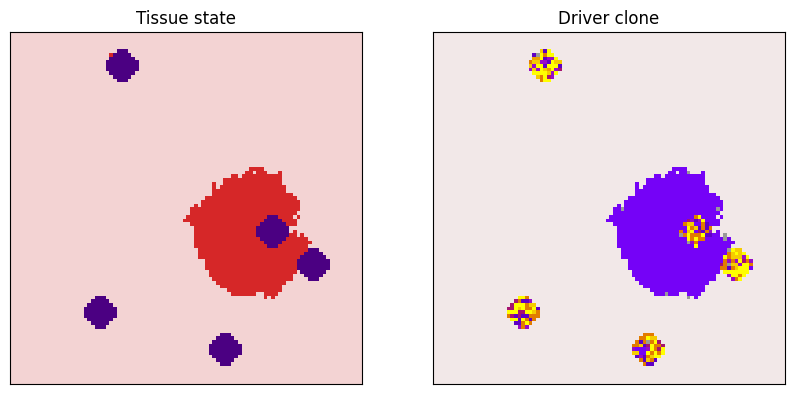

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(10, 5))
tumor.plot_tissue(ax=axes[0], color="state")
tumor.plot_tissue(ax=axes[1], color="clone", min_freq=0.05)
axes[0].set_title("Tissue state")
axes[1].set_title("Driver clone")
plt.show()

All five glands contain cancer cells, and the invasive lesion has grown around one gland and against a second.
One driver clone dominates the invasive lesion, while each gland contains a mixture of driver clones.

The driver clones keep their colors in the next two plots.
[`plot_muller`](https://pedrofale.github.io/iscc/reference/GenotypeTumor/) shows the frequency of each driver clone over time, with each clone drawn inside the parent clone.
`plot_phylogeny` shows how the driver clones descend from the founder, with each node sized by the number of cells of the driver clone.
Driver clones that never reach 5% of the cancer cells are merged into their parent.
The horizontal axis of the Muller plot counts the records of the run, one every 1.5 generations.

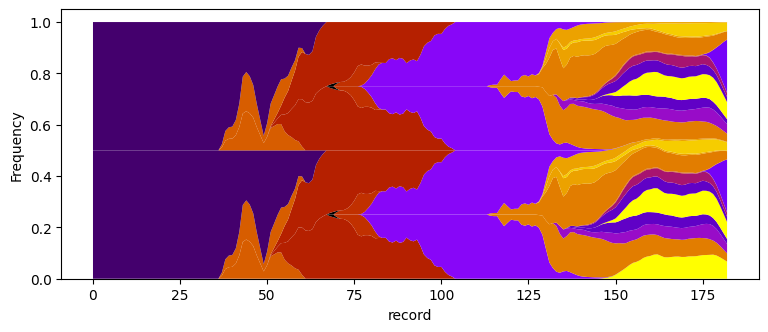

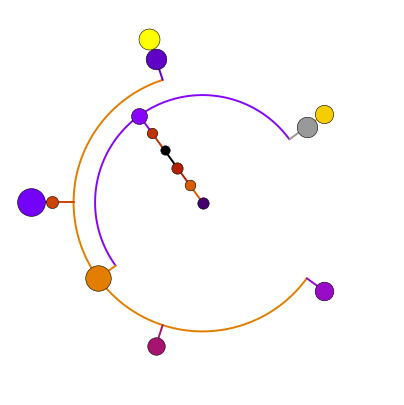

In [4]:
fig, ax = plt.subplots(figsize=(9, 3.5))
tumor.plot_muller(ax=ax, by_drivers=True, min_freq=0.05)
ax.set_xlabel("record")
plt.show()

fig, ax = plt.subplots(figsize=(5, 5))
tumor.plot_phylogeny(ax=ax, min_freq=0.05)
plt.show()

A chain of driver clones replaced one another while the founding gland was closed, and these clones form the line of nodes from the center of the phylogeny.
The tumor diversified into several driver clones after the gland opened, around record 135, when the cells spread to the other glands and into the stroma.

## Cut the specimen

We take the whole field as the resected specimen and cut it with a [`Resection`](https://pedrofale.github.io/iscc/reference/Resection/).
An in-plane cut (`bisect`) splits the specimen through the lesion into an upper and a lower part.
We dissociate the upper part into a suspension of cells for the sequencing assays, and we take a thin section of the lower part (`slice`) for Visium.
The section keeps a fifth of the cells of each deme (`depth_frac=0.2`).
`max_cells` keeps a representative subsample of 8,000 cells of the upper part, as a sequencing run takes a subsample of a suspension.
With `install=True` the sample becomes the cell table of the tumor, which the answer-key functions of `iscc.integrations` read.

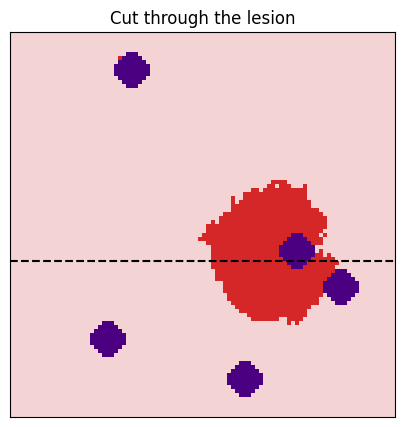

dissociated sample: 7,935 cells | Visium section: 10,032 cells


In [5]:
specimen = Resection(tumor)
upper, lower = specimen.bisect(frac=0.6, axis="y")
sample = specimen.dissociate(upper, max_cells=8000, install=True, seed=0)
section = specimen.slice(lower, depth_frac=0.2, max_cells=40_000, layers="visium")

ax = tumor.plot_tissue(color="state", figsize=(5, 5))
ax.axhline(int(0.6 * tumor.grid_size) - 0.5, color="k", ls="--")
ax.set_title("Cut through the lesion")
plt.show()
print(f"dissociated sample: {len(sample['cell_type']):,} cells | Visium section: {len(section['cell_type']):,} cells")

## Read the answer key

The table `sample["cell_type"]` gives the genotype of each cell, and `biological_types` turns the genotype into the cell type.
The table `sample["cell_gland"]` gives the gland of each cell, or -1 for a cell in the stroma, and we call gland or stroma the niche of the cell.

In [6]:
cell_type = pd.Series(biological_types(sample["cell_type"]["cell_id"]), index=sample["cell_type"].index)
niche = pd.Series(np.where(sample["cell_gland"]["gland_id"] >= 0, "gland", "stroma"), index=cell_type.index)
pd.crosstab(cell_type.rename("cell type"), niche.rename("niche"))

niche,gland,stroma
cell type,,
cancer,640,832
epithelial,268,0
stromal,0,6195


Of the 1,472 cancer cells of the sample, 640 are in glands and 832 in the stroma.

[`clones_from_clades`](https://pedrofale.github.io/iscc/reference/clones_from_clades/) labels each cancer cell with a clone, which is a clade of the true genealogy that contains at least 50 of the sampled cells.
Cancer cells above every such clade share the label `other`, and normal cells have no clone.
[`clone_summary`](https://pedrofale.github.io/iscc/reference/clone_summary/) describes each clone by the number of cells, the mutated oncogenes and tumor suppressor genes (TSGs), the division rate and the levels of the two invasion traits, breach and stromal survival.

In [7]:
clones = clones_from_clades(tumor, min_cells=50)
clone_summary(tumor, clones)[["n_cells", "n_mut_onc", "n_mut_tsg", "division_rate", "breach", "stromal_survival"]].round(3)

,n_cells,n_mut_onc,n_mut_tsg,division_rate,breach,stromal_survival
clone,,,,,,
clone_1,299,2,5,1.985,0.01,0.0
clone_2,263,2,4,1.727,0.00,0.0
clone_3,113,4,3,1.518,0.00,0.0
clone_4,101,2,5,1.985,0.01,0.0
clone_5,100,2,4,1.575,0.00,0.0
clone_6,85,2,5,1.782,0.01,0.0
clone_7,60,2,3,1.995,0.00,0.0
other,451,<NA>,<NA>,NaN,NaN,NaN


The sample contains seven clones and 451 cancer cells outside every clade.
The traits of a clone are those of the deepest genotype that all the sampled cells of the clone share.
The division rates of the clones are between 1.5 and 2.0 per generation, the ceiling set by `max_birth_rate`, and three clones carry breach at a level of 0.01.
None of the clones carries stromal survival, although more than half of the sampled cancer cells are in the stroma.

## Bulk DNA

[`bulkDNA`](https://pedrofale.github.io/iscc/reference/bulkDNA/) pools the cells of the sample into one library, by default at the depth of WGS, and reports the reads and the alternate reads at every locus.
The answer key of the assay includes the purity of the pool, which is the fraction of cancer cells in it.
A clonal heterozygous mutation in diploid cancer cells is expected at a variant allele frequency (VAF) of half the purity, and the germline variants at 0.5 and 1.

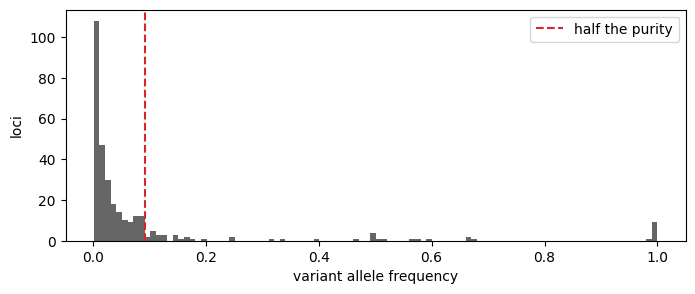

purity of the pool: 0.19


In [8]:
bulk = bulkDNA().run(sample)
vaf = bulk.observed_data.query("alt_counts > 0")["vaf"]

fig, ax = plt.subplots(figsize=(8, 3))
ax.hist(vaf, bins=100, color="0.4")
ax.axvline(bulk.purity / 2, color="tab:red", ls="--", label="half the purity")
ax.set_xlabel("variant allele frequency")
ax.set_ylabel("loci")
ax.legend()
plt.show()
print(f"purity of the pool: {bulk.purity:.2f}")

The pool has a purity of 0.19.
Most mutated loci have a VAF below half the purity, as expected for subclonal mutations, and the germline variants form the groups at 0.5 and 1.

## Single-cell DNA

[`scDNA`](https://pedrofale.github.io/iscc/reference/scDNA/) sequences 500 cells of the sample one by one, with the uneven amplification and the allelic dropout of single-cell WGS.
We sum the reads of each cell over each of the 12 segments of the genome and scale them to a mean of 2 per cell, which is a rough copy number estimate.
We show the estimate next to the true copy number of the same cells, ordered by their label, so that the clones come first, then the normal cells, and last the cancer cells outside every clade.

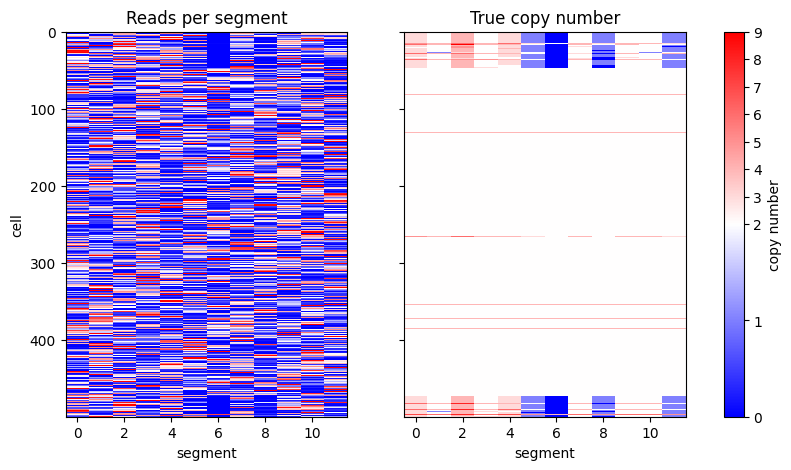

clone
clone_1     15
clone_2     11
clone_3      3
clone_4      3
clone_5      4
clone_6      7
clone_7      4
normal     426
other       27


In [9]:
dna = scDNA(n_cells=500).run(sample)
adata_dna = dna.to_anndata()
segment = adata_dna.var["segment"].values
label = clones.reindex(adata_dna.obs_names).astype(object).fillna("normal")
order = label.sort_values(kind="stable").index

reads = pd.DataFrame(adata_dna.X, index=adata_dna.obs_names).T.groupby(segment).sum().T
estimate = 2 * reads.div(reads.mean(axis=1), axis=0)
truth = pd.DataFrame(adata_dna.layers["true_cn"], index=adata_dna.obs_names).T.groupby(segment).mean().T

fig, axes = plt.subplots(1, 2, figsize=(10, 5), sharey=True)
norm = cnv_norm(truth.values)
for ax, values, title in zip(axes, (estimate, truth), ("Reads per segment", "True copy number")):
    im = ax.imshow(values.loc[order].values, aspect="auto", cmap=CNV_CMAP, norm=norm, interpolation="none")
    ax.set_title(title)
    ax.set_xlabel("segment")
axes[0].set_ylabel("cell")
fig.colorbar(im, ax=axes, label="copy number")
plt.show()
print(label.value_counts().sort_index().to_string())

Only 74 of the 500 cells are cancer cells, which reflects the purity of the sample.
The loss of both copies of segment 6 in every cancer cell stands out in the reads.
However, the uneven amplification of the default scDNA preset makes the estimate of a single cell noisy even over a whole segment, and the estimates of the diploid normal cells range far from 2.
[Shape the data](03_shape_the_data.ipynb) shows how to set the amplification and depth of the assay.

## Single-cell RNA

[`scRNA`](https://pedrofale.github.io/iscc/reference/scRNA/) draws unique molecular identifier (UMI) counts for 2,000 cells of the sample with the 10x Genomics preset.
The column `clone` of the assay gives the genotype of each cell, which we replace by the clone label.
We then run the standard scanpy workflow and color the cells by their true cell type, clone and niche.

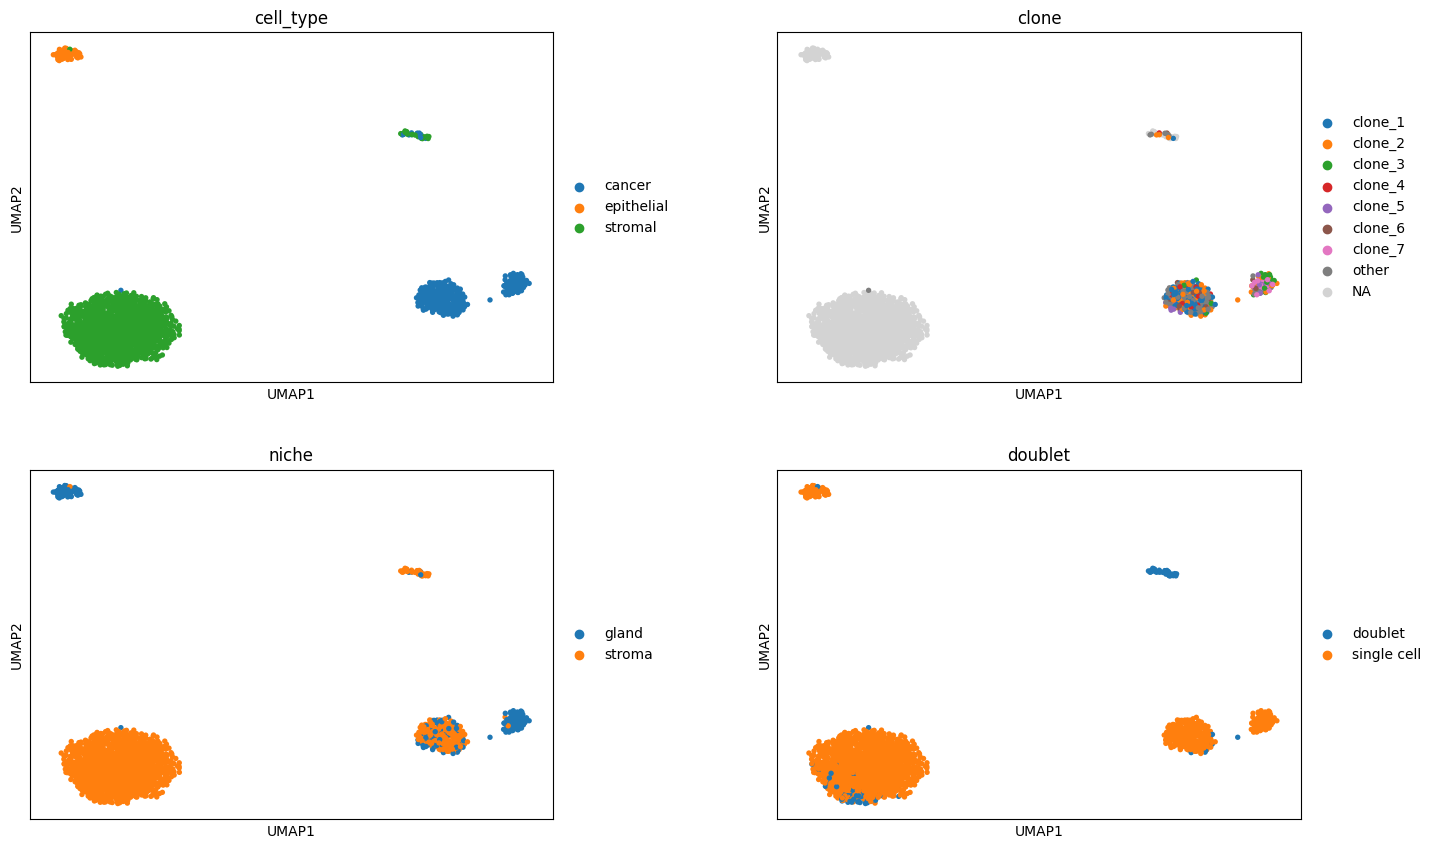

niche,gland,stroma
clone,,
clone_1,4,83
clone_2,70,0
clone_3,30,0
clone_4,0,21
clone_5,25,0
clone_6,0,20
clone_7,19,0
other,18,95


In [10]:
rna = scRNA(n_cells=2000).run(sample)
adata_rna = rna.to_anndata()
adata_rna.obs["cell_type"] = biological_types(adata_rna.obs["clone"])
adata_rna.obs["clone"] = clones.reindex(adata_rna.obs_names).values
adata_rna.obs["niche"] = niche.reindex(adata_rna.obs_names).values

sc.pp.normalize_total(adata_rna)
sc.pp.log1p(adata_rna)
sc.pp.pca(adata_rna)
sc.pp.neighbors(adata_rna)
sc.tl.umap(adata_rna)
adata_rna.obs["doublet"] = adata_rna.obs["is_doublet"].map({True: "doublet", False: "single cell"})
sc.pl.umap(adata_rna, color=["cell_type", "clone", "niche", "doublet"], ncols=2, wspace=0.3)
pd.crosstab(adata_rna.obs["clone"], adata_rna.obs["niche"])

The stromal and epithelial cells form one cluster each, and the doublets of two different cell types, which make up part of the 5% of doublets of the 10x preset, form a small cluster of their own.
The cancer cells form two clusters.
The smaller cluster contains mostly cells of clones 3 and 7, which are in glands, and the larger cluster mixes the other clones of the glands and of the stroma.
Clones 1, 4 and 6, the clones that carry breach, are the clones of the stroma.

## Visium

[`Visium`](https://pedrofale.github.io/iscc/reference/Visium/) lays the 4,992 spots of a Visium v1 slide over the section and counts the UMIs of the cells under each spot.
The section is already thin, so `section_frac=1.0` keeps all of its cells.
The answer key of a spot includes the share of each genotype among the cells under it, from which we compute the fraction of cancer cells.
We keep the spots that cover tissue and color them by their UMI count and by their true fraction of cancer cells.

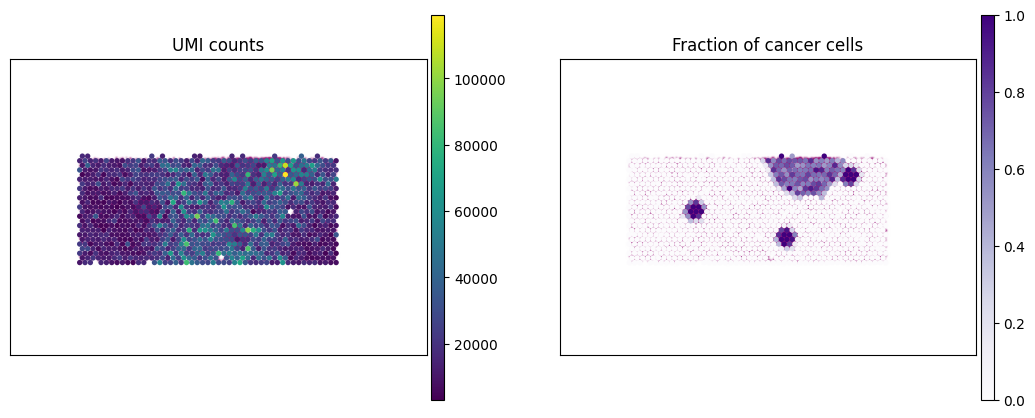

1,123 spots on tissue, median 6 cells per spot


In [11]:
visium = Visium(section_frac=1.0, seed=0).run(section)
adata_vis = visium.to_anndata()
adata_vis.obs["cancer_fraction"] = [sum(share for genotype, share in shares.items() if genotype not in normal_names)
                                    for shares in visium.clone_fracs]
adata_vis = adata_vis[adata_vis.obs["in_tissue"] == 1].copy()
library = list(adata_vis.uns["spatial"])[0]

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
sq.pl.spatial_scatter(adata_vis, color="total_counts", library_id=library, img=True, shape="circle",
                      ax=axes[0], fig=fig, title="UMI counts")
sq.pl.spatial_scatter(adata_vis, color="cancer_fraction", library_id=library, img=True, shape="circle",
                      cmap="Purples", ax=axes[1], fig=fig, title="Fraction of cancer cells")
for ax in axes:
    ax.set_xlabel("")
    ax.set_ylabel("")
plt.show()
print(f"{adata_vis.n_obs:,} spots on tissue, median {adata_vis.obs['n_cells'].median():.0f} cells per spot")

The spots of the lesion and of the three glands in the section contain mostly cancer cells, and the spots of the lesion have more UMIs than most spots of the stroma.

## Next steps

The tool tutorials run a standard method on each data set and score it against the answer key, for example [copy number from scDNA with HMMcopy](tool_hmmcopy.ipynb), [clones from bulk DNA with PyClone-VI](tool_pyclonevi.ipynb) and [cell-type deconvolution of Visium spots with RCTD](tool_rctd.ipynb).